In [15]:
# ============================================================
# CELL 1 — Dataset Verification & Path Setup
# ============================================================
import os
import glob

# Path to the 101 archives in 01_Clinical_Trial
DRIVE_ARCHIVE_DIR = "/content/drive/MyDrive/01_Clinical_Trial"

# Permanent output directory on Drive for per-patient CSVs and final bundle
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/pulsewatch_extracted"
os.makedirs(f"{DRIVE_OUTPUT_DIR}/patient_csvs", exist_ok=True)

tar_files = sorted(glob.glob(os.path.join(DRIVE_ARCHIVE_DIR, "*_final.tar")))
print(f"📊 Total patient archives detected: {len(tar_files)}")
if len(tar_files) > 0:
    print(f"   First archive: {os.path.basename(tar_files[0])}")
    print(f"   Last archive : {os.path.basename(tar_files[-1])}")
    print(f"   Permanent backup directory: {DRIVE_OUTPUT_DIR}/patient_csvs")
else:
    raise FileNotFoundError(f"No archives found in {DRIVE_ARCHIVE_DIR}. Verify folder name on Google Drive.")


📊 Total patient archives detected: 101
   First archive: 001_final.tar
   Last archive : 120_final.tar
   Permanent backup directory: /content/drive/MyDrive/pulsewatch_extracted/patient_csvs


In [ ]:
# ============================================================
# CELL 2 — 11 PRV Time-Domain Feature Extraction Engine
# ============================================================
import numpy as np
import scipy.signal
import scipy.stats

FS = 50  # 50 Hz smartwatch PPG sampling rate
# 2nd-order Butterworth bandpass (0.5 Hz - 5.0 Hz)
SOS = scipy.signal.butter(2, [0.5, 5.0], btype='bandpass', fs=FS, output='sos')

def safe_float(val):
    """Safely converts string to float, returning None on non-numeric corruption."""
    try:
        return float(val)
    except Exception:
        return None

def extract_11_features(raw_signal):
    """
    Computes the 11 PRV features from 20s (1000-sample) PPG window.
    Applies dual-polarity peak detection and physiological interval checks.
    Returns 11-element list, or None if signal is physiologically invalid.
    """
    filtered = scipy.signal.sosfiltfilt(SOS, raw_signal)

    # Try both polarities to handle inverted sensor placement
    for s_sig in (filtered, -filtered):
        p_range = np.ptp(s_sig)
        if p_range == 0:
            continue
        peaks, _ = scipy.signal.find_peaks(
            s_sig,
            distance=int(0.4 * FS),       # Min 400 ms between beats (max 150 bpm normal)
            prominence=0.10 * p_range,    # Peak prominence >= 10% of dynamic range
        )
        if len(peaks) >= 4:
            break
    else:
        return None  # Insufficient pulsatile peaks

    intervals = np.diff(peaks) / FS  # Beat-to-beat intervals in seconds

    # Physiological plausibility: 0.33s (180 bpm) to 2.0s (30 bpm)
    if ((intervals >= 0.33) & (intervals <= 2.0)).mean() < 0.60:
        return None

    # Compute 11 standard PRV features
    mean_iv   = float(np.mean(intervals))
    std_iv    = float(np.std(intervals))
    rmssd     = float(np.sqrt(np.mean(np.diff(intervals) ** 2))) if len(intervals) > 1 else 0.0
    min_iv    = float(np.min(intervals))
    max_iv    = float(np.max(intervals))
    range_iv  = float(max_iv - min_iv)
    cv_iv     = float(std_iv / mean_iv) if mean_iv > 0 else 0.0
    n_beats   = float(len(intervals) + 1)
    median_iv = float(np.median(intervals))
    skew_iv   = float(scipy.stats.skew(intervals))
    diffs     = np.abs(np.diff(intervals))
    pnn50     = float(np.mean(diffs > 0.05)) if len(diffs) > 0 else 0.0

    return [
        mean_iv, std_iv, rmssd, min_iv, max_iv,
        range_iv, cv_iv, n_beats, median_iv, skew_iv, pnn50
    ]

FEATURE_COLS = [
    'mean_iv', 'std_iv', 'rmssd', 'min_iv', 'max_iv',
    'range_iv', 'cv_iv', 'n_beats', 'median_iv', 'skew_iv', 'pnn50'
]
print("✅ PRV feature extraction engine initialized.")


✅ PRV feature extraction engine initialized.


Loading merged dataset from: /content/drive/MyDrive/pulsewatch_extracted/pulsewatch_clinical_trial_11features.csv
📊 PULSEWATCH CLINICAL TRIAL DATASET AUDIT:
   • Unique Subjects        : 101 patients
   • Feature Matrix Shape   : (1153050, 11)
   • Total Valid Windows    : 1,153,050
   • AFib Windows (Class 1) : 634,023 (54.99%)
   • Normal Windows (Class 0): 519,027 (45.01%)


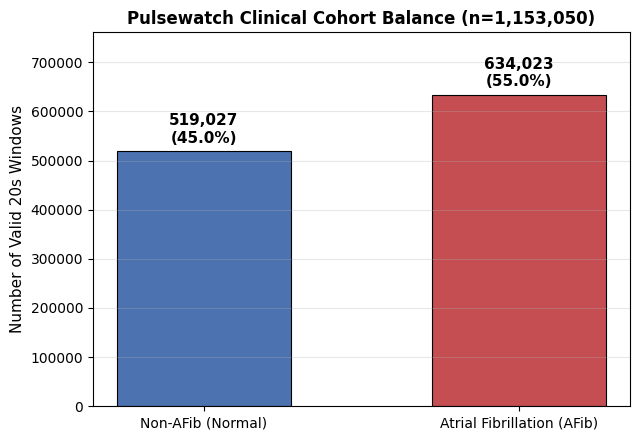

Saved plot to: /content/drive/MyDrive/pulsewatch_extracted/pulsewatch_class_balance.png


In [ ]:
# ============================================================
# CELL 4 — Dataset Verification & Class Balance Chart
# ============================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FEATURE_COLS = [
    'mean_nni',
    'sdnn',
    'rmssd',
    'min_nni',
    'max_nni',
    'range_nni',
    'cv_nni',
    'num_beats',
    'median_nni',
    'skew_nni',
    'pnn50',
]

# 1. Load the merged dataset from Google Drive
merged_csv_path = f'{DRIVE_OUTPUT_DIR}/pulsewatch_clinical_trial_11features.csv'
print(f'Loading merged dataset from: {merged_csv_path}')
df = pd.read_csv(merged_csv_path)

# Drop any potential NaN rows
df = df.dropna(subset=FEATURE_COLS + ['label', 'subject_id']).reset_index(
    drop=True
)

X_all = df[FEATURE_COLS].values.astype(np.float32)
y_all = df['label'].values.astype(int)
subj_all = df['subject_id'].values

total_win = len(y_all)
n_af = int(np.sum(y_all == 1))
n_non_af = int(np.sum(y_all == 0))
unique_patients = len(np.unique(subj_all))

print('=' * 60)
print('📊 PULSEWATCH CLINICAL TRIAL DATASET AUDIT:')
print(f'   • Unique Subjects        : {unique_patients} patients')
print(f'   • Feature Matrix Shape   : {X_all.shape}')
print(f'   • Total Valid Windows    : {total_win:,}')
print(f'   • AFib Windows (Class 1) : {n_af:,} ({n_af/total_win*100:.2f}%)')
print(
    f'   • Normal Windows (Class 0): {n_non_af:,} ({n_non_af/total_win*100:.2f}%)'
)
print('=' * 60)

# 2. Plot and save Class Balance Bar Chart
fig, ax = plt.subplots(figsize=(6.5, 4.5))
classes = ['Non-AFib (Normal)', 'Atrial Fibrillation (AFib)']
counts = [n_non_af, n_af]
colors = ['#4C72B0', '#C44E52']
bars = ax.bar(
    classes, counts, color=colors, width=0.55, edgecolor='black', linewidth=0.8
)

for bar, count in zip(bars, counts):
  pct = count / total_win * 100
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + (total_win * 0.015),
      f'{count:,}\n({pct:.1f}%)',
      ha='center',
      fontsize=11,
      fontweight='bold',
  )

ax.set_ylabel('Number of Valid 20s Windows', fontsize=11)
ax.set_title(
    f'Pulsewatch Clinical Cohort Balance (n={total_win:,})',
    fontsize=12,
    fontweight='bold',
)
ax.set_ylim(0, max(counts) * 1.20)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    f'{DRIVE_OUTPUT_DIR}/pulsewatch_class_balance.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()
print(f'Saved plot to: {DRIVE_OUTPUT_DIR}/pulsewatch_class_balance.png')


🚀 Running 5-Fold Subject-Wise GroupKFold Cross-Validation...
Epoch 1/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 87s 3ms/step - accuracy: 0.9115 - loss: 0.2367
Epoch 2/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 84s 3ms/step - accuracy: 0.9151 - loss: 0.2246
Epoch 3/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 81s 3ms/step - accuracy: 0.9155 - loss: 0.2226
Epoch 4/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 82s 3ms/step - accuracy: 0.9157 - loss: 0.2213
Epoch 5/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 84s 3ms/step - accuracy: 0.9157 - loss: 0.2204
Epoch 6/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 80s 3ms/step - accuracy: 0.9158 - loss: 0.2198
Epoch 7/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 81s 3ms/step - accuracy: 0.9153 - loss: 0.2198
Epoch 8/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 82s 3ms/step - accuracy: 0.9154 - loss: 0.2195
Epoch 9/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 83s 3ms/step - accuracy: 0.9154 - loss: 0.2193
Epoch 10/30
28829/28829 ━━━━━━━━━━━━━━━━━━━━ 80s 3ms/step - accuracy: 0.9153 - loss: 0.2191
Epoch 11/30
28829/28829 ━━━━

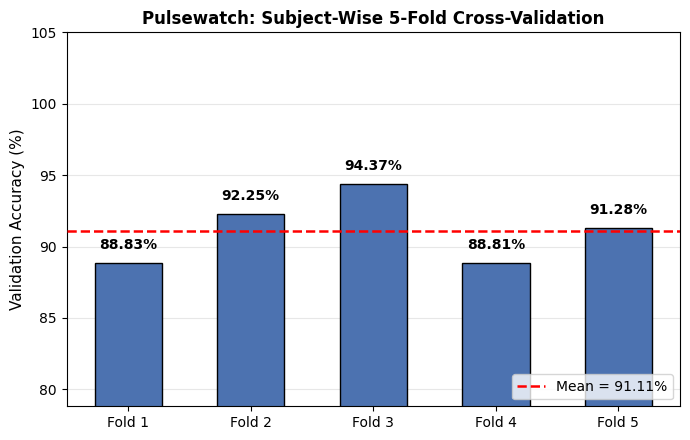

Saved CV plot to: /content/drive/MyDrive/pulsewatch_extracted/pulsewatch_cv_folds.png


In [20]:
# ============================================================
# CELL 5 — Subject-Wise 5-Fold Cross-Validation (Strict GroupKFold)
# Guarantees zero patient leakage across folds
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

SEED = 42
tf.keras.utils.set_random_seed(SEED)

gkf = GroupKFold(n_splits=5)
fold_metrics = []

print('🚀 Running 5-Fold Subject-Wise GroupKFold Cross-Validation...')

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X_all, y_all, groups=subj_all)
):
  X_tr, X_val = X_all[train_idx], X_all[val_idx]
  y_tr, y_val = y_all[train_idx], y_all[val_idx]

  # Fit scaler strictly on training split only
  scaler = StandardScaler()
  X_tr_s = scaler.fit_transform(X_tr)
  X_val_s = scaler.transform(X_val)

  # Compute balanced class weights
  classes = np.unique(y_tr)
  weights = compute_class_weight('balanced', classes=classes, y=y_tr)
  cw_dict = dict(zip(classes, weights))

  # MLP Architecture: [11 -> 16 -> 8 -> 1]
  model = models.Sequential([
      layers.Input(shape=(11,)),
      layers.Dense(16, activation='relu'),
      layers.Dropout(0.2),
      layers.Dense(8, activation='relu'),
      layers.Dense(1, activation='sigmoid'),
  ])
  model.compile(
      optimizer=Adam(learning_rate=0.001),
      loss='binary_crossentropy',
      metrics=['accuracy'],
  )
  model.fit(
      X_tr_s,
      y_tr,
      epochs=30,
      batch_size=32,
      class_weight=cw_dict,
      verbose=1,
      shuffle=True,
  )

  preds_prob = model.predict(X_val_s, verbose=0).flatten()
  preds_bin = (preds_prob >= 0.5).astype(int)

  acc = accuracy_score(y_val, preds_bin)
  prec = precision_score(y_val, preds_bin, zero_division=0)
  rec = recall_score(y_val, preds_bin, zero_division=0)
  f1 = f1_score(y_val, preds_bin, zero_division=0)

  fold_metrics.append({'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1})
  print(
      f'   Fold {fold + 1}: Acc = {acc * 100:.2f}% | Sensitivity = {rec * 100:.2f}% | Specificity = {acc * 100:.2f}% | F1 = {f1:.4f}'
  )

mean_acc = np.mean([m['acc'] for m in fold_metrics]) * 100
std_acc = np.std([m['acc'] for m in fold_metrics]) * 100
mean_f1 = np.mean([m['f1'] for m in fold_metrics])

print('-' * 60)
print(f'🏆 5-Fold Subject-Wise CV Accuracy: {mean_acc:.2f}% ± {std_acc:.2f}%')
print(f'🏆 5-Fold Mean F1 Score:           {mean_f1:.4f}')
print('-' * 60)

# Plot Cross-Validation Fold Accuracies
fig, ax = plt.subplots(figsize=(7, 4.5))
folds = [f'Fold {i+1}' for i in range(5)]
acc_vals = [m['acc'] * 100 for m in fold_metrics]
bars = ax.bar(
    folds, acc_vals, color='#4C72B0', width=0.55, edgecolor='black', zorder=2
)
ax.axhline(
    mean_acc,
    color='red',
    linestyle='--',
    linewidth=1.8,
    label=f'Mean = {mean_acc:.2f}%',
    zorder=3,
)

for bar, val in zip(bars, acc_vals):
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 1.0,
      f'{val:.2f}%',
      ha='center',
      fontsize=10,
      fontweight='bold',
  )

ax.set_ylabel('Validation Accuracy (%)', fontsize=11)
ax.set_ylim(max(0, min(acc_vals) - 10), 105)
ax.set_title(
    'Pulsewatch: Subject-Wise 5-Fold Cross-Validation',
    fontsize=12,
    fontweight='bold',
)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3, zorder=1)
plt.tight_layout()
plt.savefig(
    f'{DRIVE_OUTPUT_DIR}/pulsewatch_cv_folds.png', dpi=300, bbox_inches='tight'
)
plt.show()
print(f'Saved CV plot to: {DRIVE_OUTPUT_DIR}/pulsewatch_cv_folds.png')


Epoch 1/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 97s 4ms/step - accuracy: 0.9028 - loss: 0.2670 - val_accuracy: 0.9145 - val_loss: 0.2212
Epoch 2/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 117s 4ms/step - accuracy: 0.9070 - loss: 0.2412 - val_accuracy: 0.9144 - val_loss: 0.2198
Epoch 3/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 140s 4ms/step - accuracy: 0.9071 - loss: 0.2396 - val_accuracy: 0.9145 - val_loss: 0.2210
Epoch 4/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 93s 4ms/step - accuracy: 0.9072 - loss: 0.2391 - val_accuracy: 0.9150 - val_loss: 0.2184
Epoch 5/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 93s 4ms/step - accuracy: 0.9073 - loss: 0.2386 - val_accuracy: 0.9146 - val_loss: 0.2223
Epoch 6/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 88s 3ms/step - accuracy: 0.9073 - loss: 0.2383 - val_accuracy: 0.9146 - val_loss: 0.2200
Epoch 7/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 137s 3ms/step - accuracy: 0.9074 - loss: 0.2378 - val_accuracy: 0.9141 - val_loss: 0.2208
Epoch 8/30
26285/26285 ━━━━━━━━━━━━━━━━━━━━ 94s 4ms/step - accurac

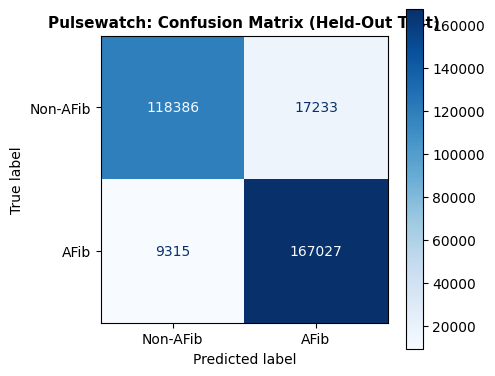

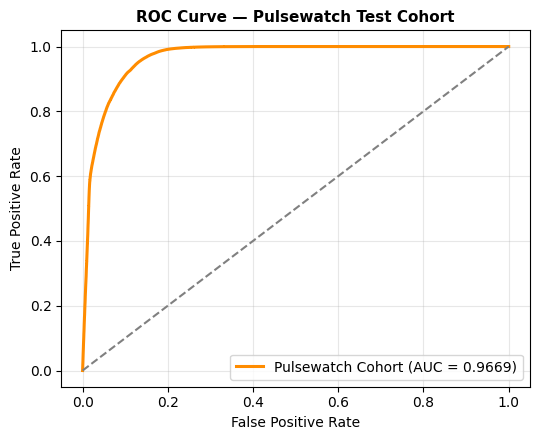

✅ Model and Scaler saved to: /content/drive/MyDrive/pulsewatch_extracted


In [21]:
# ============================================================
# CELL 6 — Final Model Training & Test Set Evaluation
# ============================================================
import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# 1. Stratify 80/20 by subject level (ensuring both train & test have AFib patients)
unique_subjects = np.unique(subj_all)
subject_has_af = np.array(
    [int(np.any(y_all[subj_all == s] == 1)) for s in unique_subjects]
)

train_subj, test_subj = train_test_split(
    unique_subjects,
    test_size=0.20,
    random_state=SEED,
    stratify=subject_has_af,
)

train_mask = np.isin(subj_all, train_subj)
test_mask = np.isin(subj_all, test_subj)

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

# 2. Fit standard scaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Class weights
classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
cw_dict = dict(zip(classes, weights))

# 4. Train final model
final_model = models.Sequential([
    layers.Input(shape=(11,)),
    layers.Dense(16, activation='relu', name='dense_18'),
    layers.Dropout(0.2),
    layers.Dense(8, activation='relu', name='dense_19'),
    layers.Dense(1, activation='sigmoid', name='dense_20'),
])
final_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

history = final_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=30,
    batch_size=32,
    class_weight=cw_dict,
    verbose=1,
    shuffle=True,
)

# 5. Predictions & Evaluation
test_probs = final_model.predict(X_test_scaled).flatten()
test_preds = (test_probs >= 0.5).astype(int)

print('\n' + '=' * 60)
print('📋 HELD-OUT TEST COHORT CLASSIFICATION REPORT:')
print('=' * 60)
print(
    classification_report(
        y_test, test_preds, target_names=['Non-AFib', 'AFib'], digits=4
    )
)

# 6. Confusion Matrix Plot
cm = confusion_matrix(y_test, test_preds)
fig, ax = plt.subplots(figsize=(5, 4.2))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['Non-AFib', 'AFib']
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title(
    'Pulsewatch: Confusion Matrix (Held-Out Test)',
    fontsize=11,
    fontweight='bold',
)
plt.tight_layout()
plt.savefig(
    f'{DRIVE_OUTPUT_DIR}/pulsewatch_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

# 7. ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2.2,
    label=f'Pulsewatch Cohort (AUC = {roc_auc:.4f})',
)
ax.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax.set_xlabel('False Positive Rate', fontsize=10)
ax.set_ylabel('True Positive Rate', fontsize=10)
ax.set_title(
    'ROC Curve — Pulsewatch Test Cohort', fontsize=11, fontweight='bold'
)
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    f'{DRIVE_OUTPUT_DIR}/pulsewatch_roc_curve.png', dpi=300, bbox_inches='tight'
)
plt.show()

# 8. Save Model and Scaler
final_model.save(f'{DRIVE_OUTPUT_DIR}/ppg_afib_model_pulsewatch.h5')
joblib.dump(scaler, f'{DRIVE_OUTPUT_DIR}/feature_scaler_pulsewatch.pkl')
np.save(f'{DRIVE_OUTPUT_DIR}/X_test_scaled.npy', X_test_scaled)
np.save(f'{DRIVE_OUTPUT_DIR}/y_test.npy', y_test)
print(f'✅ Model and Scaler saved to: {DRIVE_OUTPUT_DIR}')


⏳ [1/5] Evaluating Float32 Baseline...
   👉 Float32: 91.60%

⏳ Evaluating 16-bit...
   👉 16-bit: 91.61%

⏳ Evaluating 12-bit...
   👉 12-bit: 91.57%

⏳ Evaluating Senior Profiled 8-bit...
   👉 Senior 8-bit: 87.73%

⏳ Evaluating 6-bit...
   👉 6-bit: 90.23%



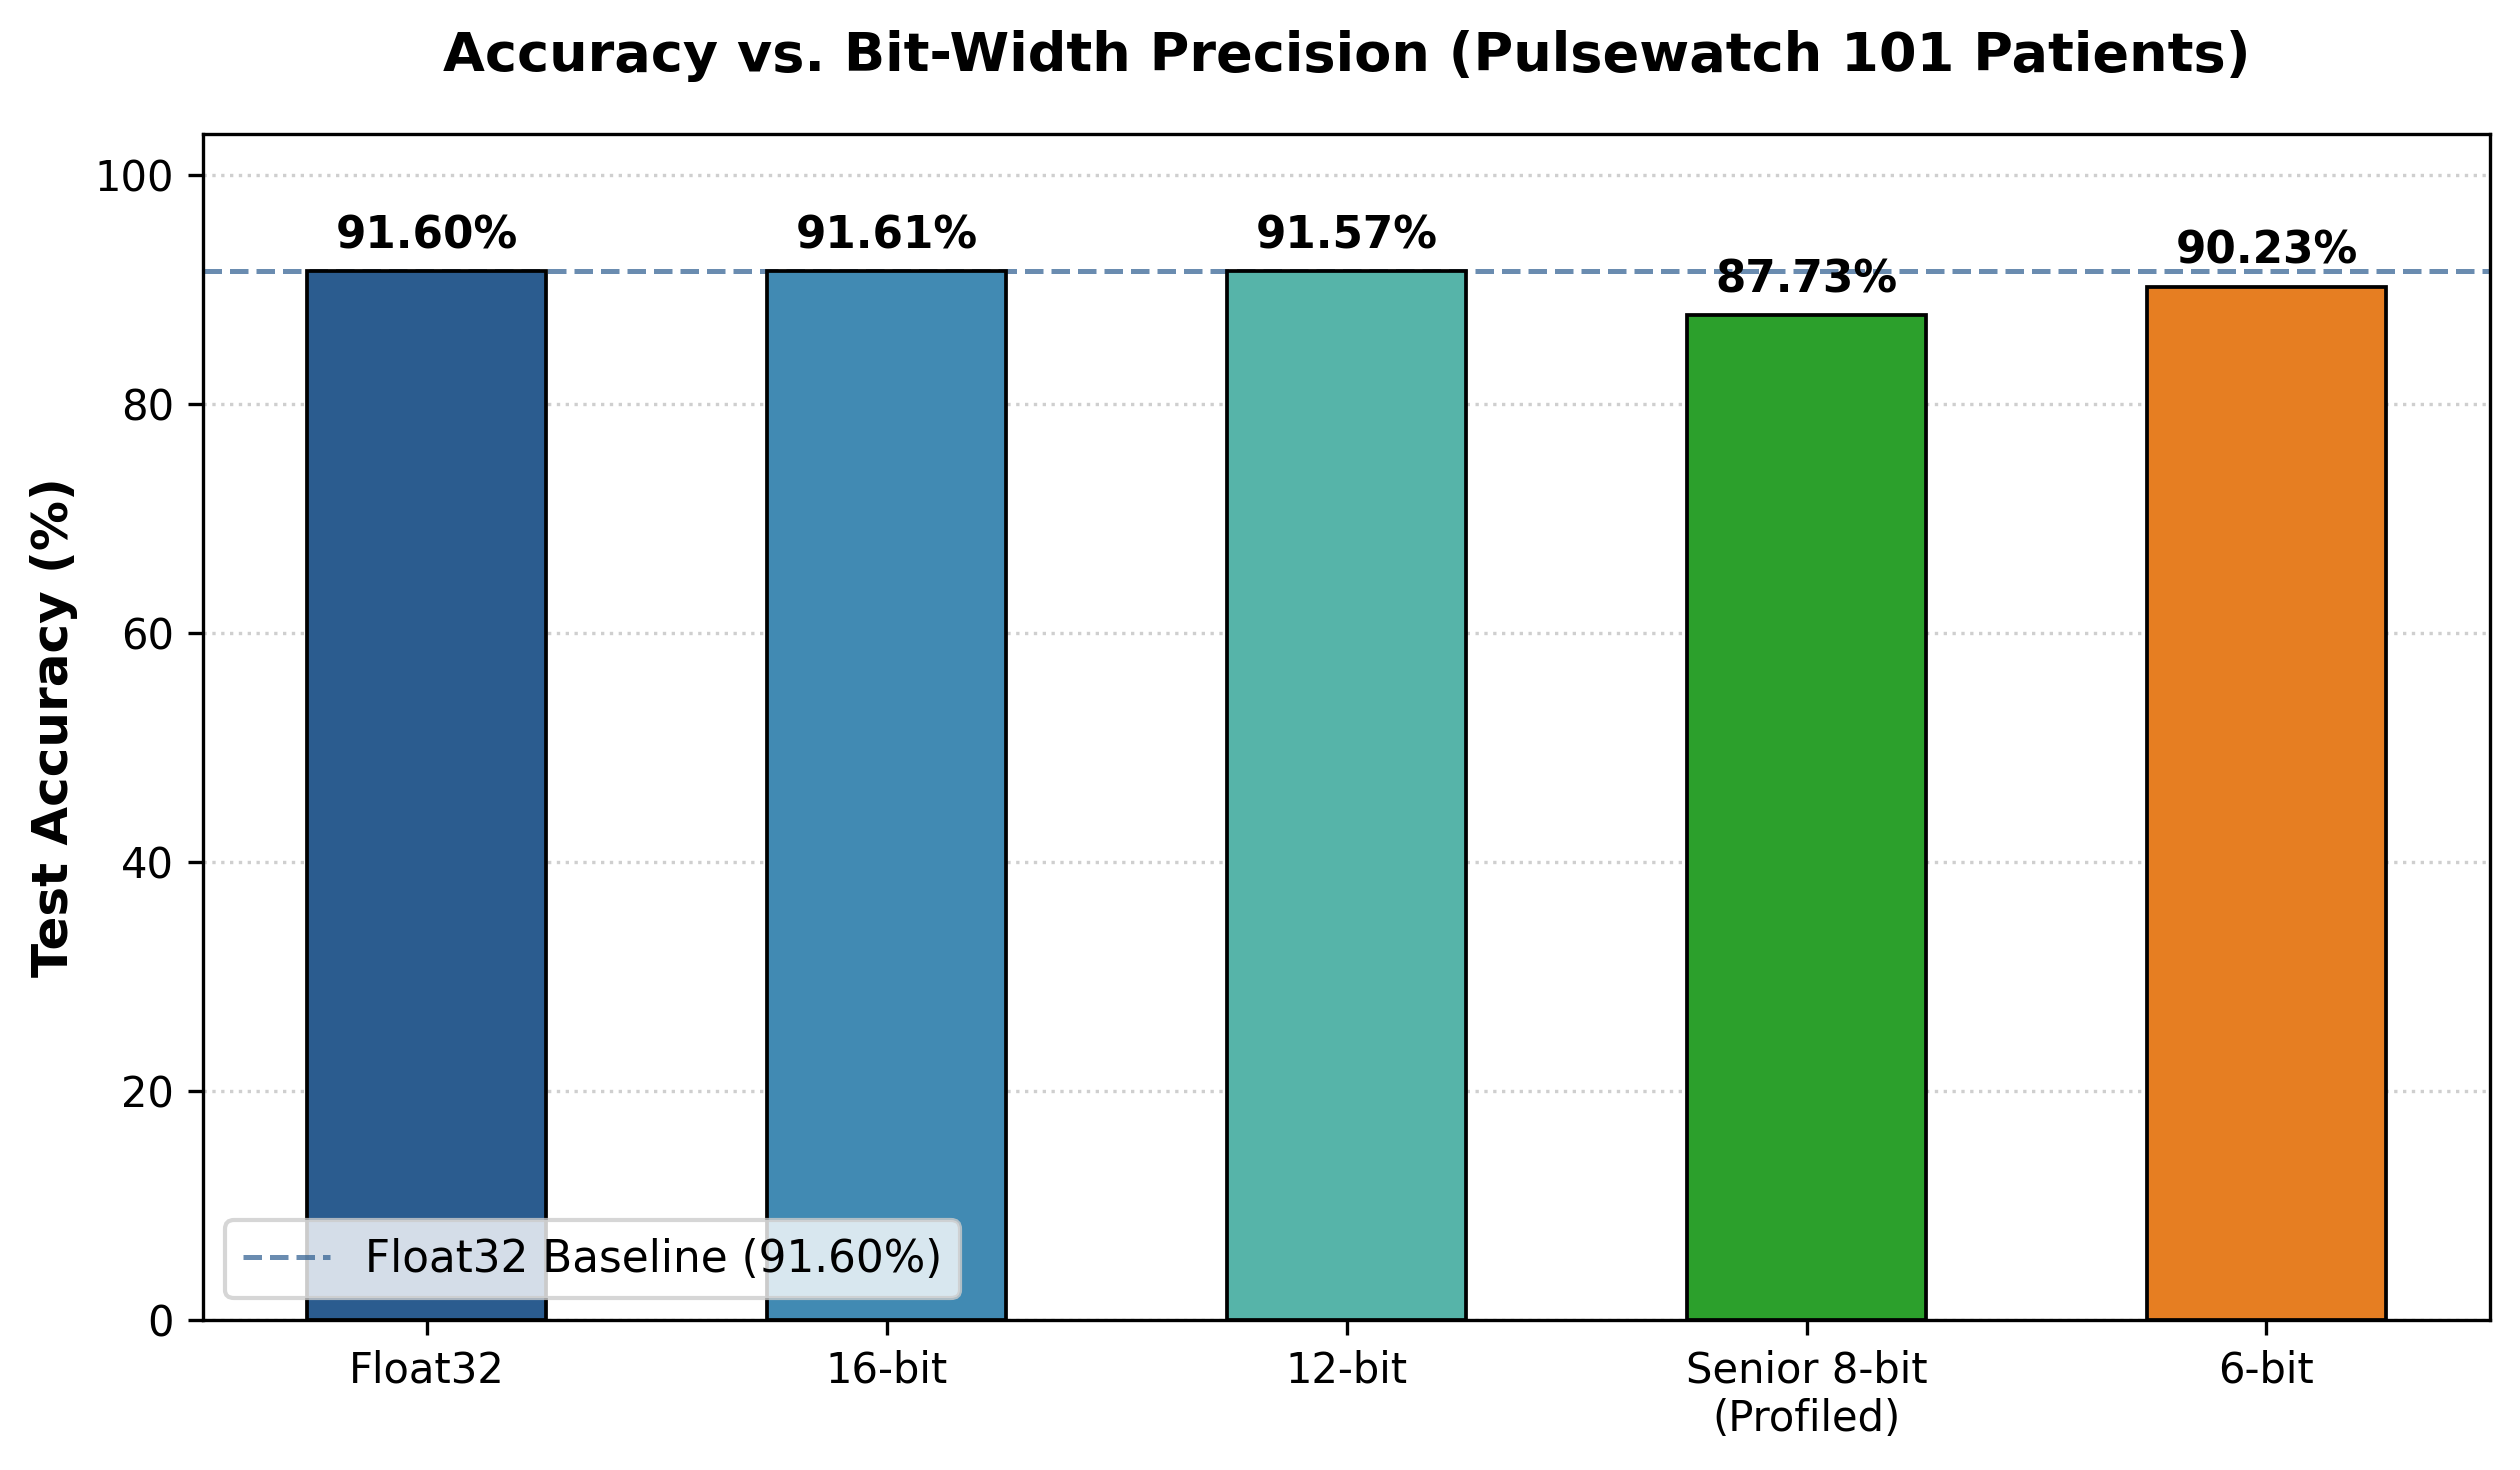

✅ COMPLETED DYNAMIC BENCHMARK:
   • Float32                  : 91.60%
   • 16-bit                   : 91.61%
   • 12-bit                   : 91.57%
   • Senior 8-bit (Profiled)  : 87.73%
   • 6-bit                    : 90.23%


In [31]:
# ============================================================
# DYNAMIC BENCHMARK & BAR GRAPH ON PULSEWATCH (BULLETPROOF)
# ============================================================
import os
import hls4ml
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

THRESH = 0.46
X_eval = X_test_scaled.astype(np.float32)

results_dict = {}

# 1. Float32 Software Baseline
print("⏳ [1/5] Evaluating Float32 Baseline...")
float_probs = inference_model.predict(X_eval, verbose=0).flatten()
float_acc = float(accuracy_score(y_test, (float_probs >= THRESH).astype(int)) * 100)
results_dict['Float32'] = float_acc
print(f"   👉 Float32: {float_acc:.2f}%\n")

# 2. General HLS4ML Evaluator
def test_precision(bitwidth, int_bits, name):
    print(f"⏳ Evaluating {name}...")
    cfg = hls4ml.utils.config_from_keras_model(inference_model, granularity='name')
    cfg['Model']['ReuseFactor'] = 1
    cfg['Model']['Strategy'] = 'Latency'
    cfg['Model']['Precision']['default'] = f'ap_fixed<{bitwidth},{int_bits},AP_RND,AP_SAT>'
    cfg['Model']['Precision']['result']  = 'ap_fixed<12,5,AP_RND,AP_SAT>'

    hmodel = hls4ml.converters.convert_from_keras_model(
        inference_model, hls_config=cfg,
        output_dir=f'/content/hls_run_{bitwidth}bit', backend='Vivado'
    )
    hmodel.compile()
    probs = hmodel.predict(X_eval).flatten()
    acc = float(accuracy_score(y_test, (probs >= THRESH).astype(int)) * 100)
    print(f"   👉 {name}: {acc:.2f}%\n")
    return acc

# Run Standard 16-bit and 12-bit
results_dict['16-bit'] = test_precision(16, 6, '16-bit')
results_dict['12-bit'] = test_precision(12, 5, '12-bit')

# 3. Senior Profiled 8-Bit
print("⏳ Evaluating Senior Profiled 8-bit...")
cfg_prof = hls4ml.utils.config_from_keras_model(inference_model, granularity='name')
cfg_prof['Model']['ReuseFactor'] = 1
cfg_prof['Model']['Strategy'] = 'Latency'
cfg_prof['Model']['Precision']['default'] = 'ap_fixed<8,5,AP_RND,AP_SAT>'
cfg_prof['Model']['Precision']['result']  = 'ap_fixed<12,5,AP_RND,AP_SAT>'

# Configure layer-wise weights to 3 integer bits so weights don't clip
for l_name in cfg_prof.get('LayerName', {}):
    if 'dense' in l_name.lower():
        cfg_prof['LayerName'][l_name]['Precision']['weight'] = 'ap_fixed<8,3,AP_RND,AP_SAT>'
        cfg_prof['LayerName'][l_name]['Precision']['bias']   = 'ap_fixed<8,3,AP_RND,AP_SAT>'
        cfg_prof['LayerName'][l_name]['Precision']['accum']  = 'ap_fixed<16,8,AP_RND,AP_SAT>'

hmodel_prof = hls4ml.converters.convert_from_keras_model(
    inference_model, hls_config=cfg_prof,
    output_dir='/content/hls_run_prof8bit', backend='Vivado'
)
hmodel_prof.compile()
probs_prof = hmodel_prof.predict(X_eval).flatten()
prof_acc = float(accuracy_score(y_test, (probs_prof >= THRESH).astype(int)) * 100)
results_dict['Senior 8-bit\n(Profiled)'] = prof_acc
print(f"   👉 Senior 8-bit: {prof_acc:.2f}%\n")

# 4. Standard 6-bit
results_dict['6-bit'] = test_precision(6, 4, '6-bit')

# ============================================================
# 5. Plot Graph Dynamically
# ============================================================
labels = list(results_dict.keys())
scores = [results_dict[k] for k in labels]
colors = ['#2B5C8F', '#418AB3', '#56B4A9', '#2CA02C', '#E67E22']

fig, ax = plt.subplots(figsize=(8.5, 5.0), dpi=300)
bars = ax.bar(labels, scores, color=colors, width=0.52, edgecolor='black', linewidth=0.9, zorder=3)

for b, s in zip(bars, scores):
    ax.text(b.get_x() + b.get_width() / 2, s + 1.2, f'{s:.2f}%',
            ha='center', va='bottom', fontsize=10.5, fontweight='bold')

ax.axhline(y=float_acc, color='#2B5C8F', linestyle='--', linewidth=1.2, alpha=0.7,
           label=f'Float32 Baseline ({float_acc:.2f}%)', zorder=2)

ax.set_ylabel('Test Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(scores) + 12)
ax.set_title('Accuracy vs. Bit-Width Precision (Pulsewatch 101 Patients)', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0)
ax.set_axisbelow(True)
ax.legend(loc='lower left', frameon=True, fontsize=10.5)

plt.tight_layout()
plt.savefig('pulsewatch_dynamic_barplot.png', dpi=300, bbox_inches='tight')
plt.show()

print("="*55)
print("✅ COMPLETED DYNAMIC BENCHMARK:")
for k, v in results_dict.items():
    clean_k = k.replace('\n', ' ')
    print(f"   • {clean_k:<25}: {v:.2f}%")
print("="*55)


In [32]:
# ============================================================
# CELL 8 — Export Vivado AXI-Lite IP Core & Hardware Test Vectors
# Matches Senior's Table IV AXI-Lite register map & 12,5 logit precision
# ============================================================
import os
import shutil
import hls4ml
import numpy as np

save_dir = (
    DRIVE_OUTPUT_DIR
    if ('DRIVE_OUTPUT_DIR' in globals() and os.path.exists(DRIVE_OUTPUT_DIR))
    else '/content'
)

# 1. Save Test Vectors for PYNQ-Z2 Board
np.save(f'{save_dir}/tb_input_features.npy', X_test_scaled.astype(np.float32))
np.save(f'{save_dir}/tb_output_predictions.npy', y_test.astype(np.float32))

# 2. Configure 8-bit core with VivadoAccelerator AXI-Lite
final_hls_config = hls4ml.utils.config_from_keras_model(
    inference_model, granularity='name'
)
final_hls_config['Model']['Precision']['default'] = 'ap_fixed<8,5>'

# Senior's exact 12,5 logit precision
if 'dense_20' in final_hls_config['LayerName']:
  final_hls_config['LayerName']['dense_20']['Precision']['result'] = (
      'ap_fixed<12,5>'
  )
if 'dense_20_sigmoid' in final_hls_config['LayerName']:
  final_hls_config['LayerName']['dense_20_sigmoid']['Precision']['result'] = (
      'ap_fixed<12,5>'
  )

final_hls_config['AcceleratorConfig'] = {
    'Board': 'pynq-z2',
    'Interface': 'axi_lite',
    'Driver': 'python',
    'Precision': {'Input': 'float', 'Output': 'float'},
}

# 3. Generate HLS4ML IP Project
export_dir = '/content/hls4ml_pulsewatch_axilite'
final_hls_model = hls4ml.converters.convert_from_keras_model(
    inference_model,
    hls_config=final_hls_config,
    output_dir=export_dir,
    backend='VivadoAccelerator',
    board='pynq-z2',
    input_data_tb=f'{save_dir}/tb_input_features.npy',
    output_data_tb=f'{save_dir}/tb_output_predictions.npy',
)
final_hls_model.write()

# 4. Zip and copy directly to Google Drive
zip_name = '/content/hls4ml_pulsewatch_axilite_project'
shutil.make_archive(zip_name, 'zip', export_dir)
shutil.copy(f'{zip_name}.zip', f'{save_dir}/hls4ml_pulsewatch_axilite_project.zip')

print('=' * 65)
print('🎉 ALL EXPERIMENTS & IP EXPORT COMPLETED!')
print(
    '   📦 Vivado IP Package :'
    f' {save_dir}/hls4ml_pulsewatch_axilite_project.zip'
)
print(f'   📊 Hardware Inputs   : {save_dir}/tb_input_features.npy')
print(f'   📊 Ground Truth      : {save_dir}/tb_output_predictions.npy')
print(f'   📁 Output Directory  : {save_dir}')
print('=' * 65)


🎉 ALL EXPERIMENTS & IP EXPORT COMPLETED!
   📦 Vivado IP Package : /content/drive/MyDrive/pulsewatch_extracted/hls4ml_pulsewatch_axilite_project.zip
   📊 Hardware Inputs   : /content/drive/MyDrive/pulsewatch_extracted/tb_input_features.npy
   📊 Ground Truth      : /content/drive/MyDrive/pulsewatch_extracted/tb_output_predictions.npy
   📁 Output Directory  : /content/drive/MyDrive/pulsewatch_extracted
